# Orthogonalization of narratives

```
@article{lehalle2025orth,
  title={Orthogonalization of narratives},
  author={Lehalle, Charles-Albert},
  journal={Goolge Colab Notebook},
  year={2025},
  month={12
}
```

## Looking for data

With GPT: https://chatgpt.com/c/694abfc5-c2f8-8326-8475-c5f7ca8e042f or with perplecity: https://www.perplexity.ai/search/i-am-a-professor-at-university-7uTq_EHMQRyrtQeOwAwmMg

# Get the data

https://www.kaggle.com/datasets/rmisra/news-category-dataset/data

> This dataset contains around 210k news headlines from 2012 to 2022 from HuffPost. This is one of the biggest news datasets and can serve as a benchmark for a variety of computational linguistic tasks. HuffPost stopped maintaining an extensive archive of news articles sometime after this dataset was first collected in 2018, so it is not possible to collect such a dataset in the present day. Due to changes in the website, there are about 200k headlines between 2012 and May 2018 and 10k headlines between May 2018 and 2022.

```
@article{misra2022news,
  title={News Category Dataset},
  author={Misra, Rishabh},
  journal={arXiv preprint arXiv:2209.11429},
  year={2022}
}
```

In [40]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rmisra/news-category-dataset")

print("Path to dataset files:", path)

Path to dataset files: /users/eleves-b/2023/juliette.anglade/.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3


In [41]:
fname = '/users/eleves-b/2023/juliette.anglade/.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3'

import pandas
import pandas as pd
import json
import os

files_in_dir = os.listdir(fname)
print(f"Files in directory: {files_in_dir}")

full_path = os.path.join(fname, 'News_Category_Dataset_v3.json')

# Method 1: Using read_json with lines=True
NCD3_df = pandas.read_json(full_path, lines=True)

# Display basic information
print(f"Dataset shape: {NCD3_df.shape}")
print(f"\nColumn names: {NCD3_df.columns.tolist()}")
print(f"\nFirst few rows:")
NCD3_df.sample(3)

Files in directory: ['News_Category_Dataset_v3.json']
Dataset shape: (209527, 6)

Column names: ['link', 'headline', 'category', 'short_description', 'authors', 'date']

First few rows:


,link,headline,category,short_description,authors,date
21002,https://www.huffingtonpost.com/entry/donald-tr...,Trump Backs Saudi Leaders During Mass Purge,POLITICS,"""Some of those they are harshly treating have ...",Nick Visser,2017-11-07
27823,https://www.huffingtonpost.com/entry/to-win-de...,"To Win, Democrats Don’t Need Trump Voters",POLITICS,"Yesterday, New York Times columnist Thomas Fri...","Canton Winer, ContributorFreelance Writer, Soc...",2017-08-11
20728,https://www.huffingtonpost.com/entry/murder-in...,Murder In The Hague: Saudi-Iranian Proxy War H...,WORLD NEWS,By James M. Dorsey Shot dead this week on a st...,"James M. Dorsey, ContributorS. Rajaratnam Scho...",2017-11-10


<Axes: xlabel='date'>

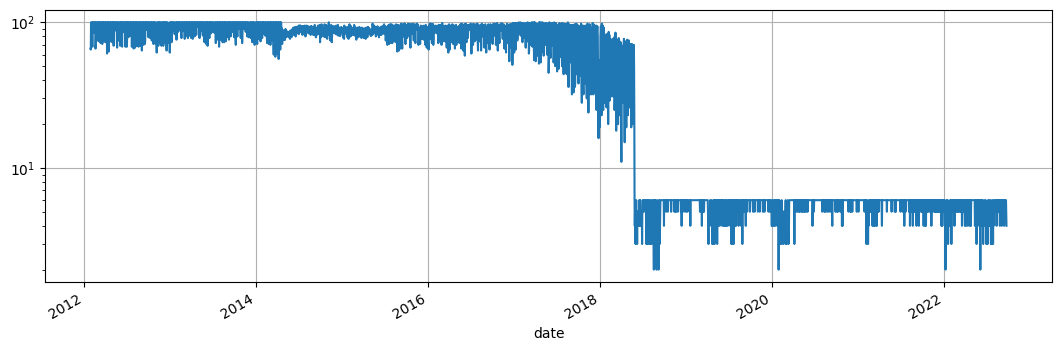

In [42]:
NCD3_df.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

In [39]:
NCD3_df.category.value_counts()[:7]

category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
Name: count, dtype: int64

In [43]:
news_subset_df = NCD3_df[NCD3_df.category.isin(['POLITICS', 'ENTERTAINMENT', 'TRAVEL', 'PARENTING'])]
news_subset_df.sample(3)

,link,headline,category,short_description,authors,date
170016,https://www.huffingtonpost.com/entry/teach-you...,Teach Your Wired Children About Healthy Relati...,PARENTING,There is a place for children to have online r...,"Dr. Jim Taylor, Contributor\nSport psychologis...",2013-03-27
93167,https://www.huffingtonpost.com/entry/michael-c...,Donald Trump's Lawyer Apologizes For 'Inarticu...,ENTERTAINMENT,He also threatened The Daily Beast for publish...,Paige Lavender,2015-07-28
49128,https://www.huffingtonpost.com/entry/john-lege...,John Legend Goes In Chrissy Teigen Drag To Ree...,ENTERTAINMENT,All of me wants all of this.,Cole Delbyck,2016-12-08


<Axes: xlabel='date'>

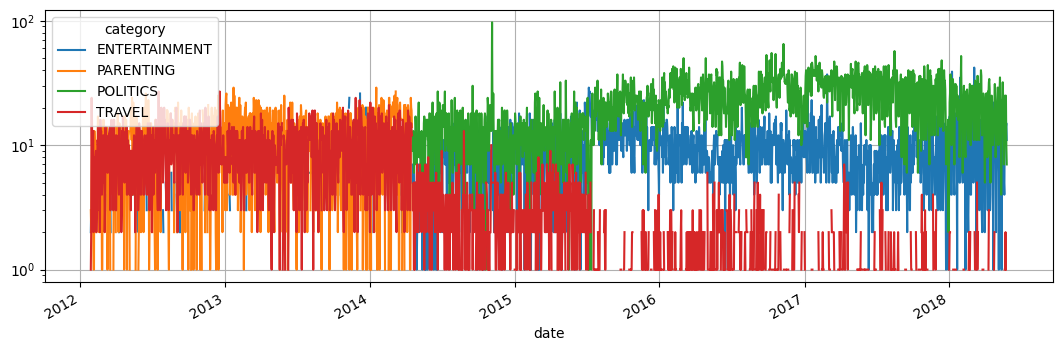

In [44]:
daily_politics_df = news_subset_df.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=True,
)

# prepare modernBERT and run it on three narratives

In [45]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

#from google.colab import files


In [46]:
# Initialize ModernBERT model and tokenizer
print("Loading ModernBERT model...")
model_name = "answerdotai/ModernBERT-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

def get_embedding(text, tokenizer, model, device):
    """
    Generate embedding for a given text using ModernBERT.
    Uses mean pooling of the last hidden state.
    """
    # Tokenize and prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get embeddings
    with torch.no_grad():
        outputs = model(**inputs)
        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()


Loading ModernBERT model...


In [47]:
narratives_politics = {
    "trump": # "Donald Trump’s election was framed as the result of widespread voter frustration with political elites, economic insecurity in post-industrial regions, and a backlash against globalization and cultural change. His populist rhetoric, direct communication style, and ability to dominate media attention allowed him to mobilize disaffected voters who felt ignored by traditional parties and institutions.",
    "Donald Trump will be elected because widespread economic discontent, distrust of political elites, and cultural backlash against globalization and immigration fuel support for an outsider candidate who promises disruption, national restoration, and direct confrontation with established institutions and media.",
    "obama": #"Barack Obama’s re-election was attributed to a gradual economic recovery after the financial crisis, strong support from minority and younger voters, and the successful framing of his opponent as disconnected from middle-class concerns. His campaign emphasized continuity, social progress, and the defense of healthcare reform while leveraging effective grassroots mobilization and data-driven campaigning.",
    "Barack Obama will be re-elected because a slowly recovering economy, the successful framing of policy achievements such as healthcare reform, and strong coalition support among minorities, younger voters, and urban populations outweigh voter dissatisfaction and sustain confidence in incremental progress.",
    "obamacare": "The Affordable Care Act, often called Obamacare, is needed because it expands access to health insurance for millions of people who were previously uninsured or underinsured. The law aims to reduce healthcare costs over time, protect individuals with preexisting conditions, and strengthen the healthcare system by spreading risk more broadly across the population.",
}
narratives_society = {
    "black_lives": "Black Lives Matter emerged as a movement responding to systemic racism, police violence, and unequal treatment of Black Americans within the criminal justice system. It connected individual incidents of violence to broader structural inequalities, using protests, social media, and cultural discourse to demand accountability, reform, and recognition of racial injustice in American society.",
    "shooting": "Mass shootings in the United States persist because of the widespread availability of firearms, gaps in mental health support, social isolation, media amplification of violence, and political gridlock that prevents comprehensive gun policy reform despite recurring public outrage.",
    "data_privacy": "Data privacy is important because personal information is increasingly collected, stored, and analyzed by governments and private companies, often without clear consent or transparency. Protecting data privacy helps preserve individual autonomy, prevents misuse and surveillance, and maintains trust in digital technologies that shape modern economic, social, and political life.",
    "paris_agree.": "The Paris Agreement is important because it represents a global commitment to limit climate change by reducing greenhouse gas emissions and promoting international cooperation. By setting shared goals and encouraging accountability, the agreement aims to mitigate the environmental, economic, and social risks associated with rising global temperatures and extreme weather events.,",
    "shooting": "There are many ways to prevent school shootings because the issue involves multiple social, psychological, and policy factors. Approaches such as improving mental health support, enhancing school safety measures, fostering community engagement, and addressing access to firearms can collectively reduce the risk of violence.",
}
narratives_geopolitics = {
    "ISIS": "ISIS attacks are happening because of prolonged instability in parts of the Middle East, power vacuums created by war, and sectarian divisions that extremist groups exploit. The organization uses violence and terrorism to assert control, spread fear, and gain international attention, while drawing recruits through ideological propaganda and grievances linked to political and economic marginalization.",
    "Russia": "Russia is annexing Crimea because of strategic and political interests tied to regional influence, military access to the Black Sea, and concerns about Ukraine’s alignment with Western institutions. The move follows political instability in Ukraine and is justified by Russian authorities as protecting ethnic Russians and national security, while being widely viewed internationally as a violation of Ukrainian sovereignty.",
    "Brexit": "The United Kingdom votes to leave the European Union because of long-standing concerns about national sovereignty, immigration, and the perceived loss of democratic control to EU institutions. Economic uncertainty, regional inequality, and dissatisfaction with political elites also contribute to a referendum outcome driven by competing visions of globalization and national identity.",
}
narratives_entertainment = {
    "GoT": "Game of Thrones is innovative because it combines cinematic production values with long-form television storytelling, complex characters, and morally ambiguous narratives. By subverting traditional fantasy tropes and embracing unpredictability, the series reshaped audience expectations and helped elevate television as a medium for ambitious, high-budget storytelling.",
    "me_too": "The Me Too movement is a revolution because it fundamentally changes how sexual harassment and abuse are discussed, exposing systemic power imbalances across industries. By amplifying personal testimony and collective accountability, the movement challenges long-standing norms of silence and reshapes cultural and institutional responses to misconduct.",
    "stream_music": "Streaming-first music releases are changing the industry because they shift power away from traditional distribution models toward digital platforms and data-driven consumption. This approach alters how artists release, promote, and monetize music, emphasizing continuous engagement, algorithmic visibility, and global accessibility over physical sales and scheduled releases.",
}
narratives_travel = {
    "MH370": "The disappearance of Malaysia Airlines Flight MH370 is terrible because it represents a profound human tragedy marked by uncertainty, loss, and unanswered questions. The incident exposed vulnerabilities in global aviation tracking and left families and the international community without clear explanations or closure.",
    "airlines": "Airlines push premium economy seating and loyalty-program changes because they seek to increase revenue in a highly competitive industry facing rising costs and thin margins. By segmenting passengers and monetizing comfort and perks, airlines aim to maximize profits while adapting to changing traveler expectations and spending behavior.",
    "rentals": "Cities begin regulating short-term rentals because rapid growth of platforms like Airbnb affects housing availability, neighborhood stability, and local infrastructure. Policymakers respond to concerns about rising rents, tourism pressure, and fairness between traditional hotels and peer-to-peer accommodations.",
    "ebola": "Ebola is dangerous because it is a highly contagious and often fatal disease that can spread rapidly in areas with limited healthcare infrastructure. Outbreaks generate fear, disrupt travel and economies, and highlight global vulnerabilities in disease detection, containment, and public health preparedness.",
}
narratives_parenting = {
    "same_sex": "Same-sex marriage is a revolution because it fundamentally reshapes legal definitions of family, equality, and civil rights. By extending marriage protections to LGBTQ+ couples, it challenges long-standing social norms and affirms the principle that legal recognition should not depend on sexual orientation.",
    "parental_leave": "Paid parental leave is a change because it redefines the relationship between work, family, and economic security. By allowing parents time to care for newborns without losing income or employment, it shifts expectations about caregiving responsibilities and workplace support for families.",
    "screen_time": "Screen time for teens is dangerous because excessive use of digital devices can affect mental health, sleep patterns, and social development. Constant exposure to social media and online comparison may increase anxiety, reduce attention, and shape behavior during a critical stage of emotional growth.",
}


In [48]:
narratives_themes = ['politics', 'society', 'geopolitics', 'entertainment', 'travel', 'parenting']


In [49]:
# Step 1: Compute embeddings for the three narratives
print("Computing narrative embeddings...")
narrative_embeddings = {}
all_narratives = []
for theme in narratives_themes:
  narratives = globals()[f"narratives_{theme}"]
  for name, text in narratives.items():
      embedding = get_embedding(text, tokenizer, model, device)
      all_narratives.append({
          'theme': theme,
          'name': name,
          'embedding': embedding,
      })
      print(f"  {name}: embedding shape {embedding.shape}")

all_narratives_df = pandas.DataFrame(all_narratives)

narrative_matrix = np.array(all_narratives_df['embedding'].to_list())
print(f"\nOriginal narrative matrix shape: {narrative_matrix.shape}")

all_narratives_df.sample(3)

Computing narrative embeddings...
  trump: embedding shape (768,)
  obama: embedding shape (768,)
  obamacare: embedding shape (768,)
  black_lives: embedding shape (768,)
  shooting: embedding shape (768,)
  data_privacy: embedding shape (768,)
  paris_agree.: embedding shape (768,)
  ISIS: embedding shape (768,)
  Russia: embedding shape (768,)
  Brexit: embedding shape (768,)
  GoT: embedding shape (768,)
  me_too: embedding shape (768,)
  stream_music: embedding shape (768,)
  MH370: embedding shape (768,)
  airlines: embedding shape (768,)
  rentals: embedding shape (768,)
  ebola: embedding shape (768,)
  same_sex: embedding shape (768,)
  parental_leave: embedding shape (768,)
  screen_time: embedding shape (768,)

Original narrative matrix shape: (20, 768)


,theme,name,embedding
14,travel,airlines,"[-0.41076818, -0.57880586, -0.7877439, 0.11831..."
11,entertainment,me_too,"[-0.12336282, -1.1742824, -0.2515916, 0.475935..."
0,politics,trump,"[-0.21873805, -0.753228, -0.28103217, 0.136313..."


In [50]:
all_narratives_df.name.to_list()

['trump',
 'obama',
 'obamacare',
 'black_lives',
 'shooting',
 'data_privacy',
 'paris_agree.',
 'ISIS',
 'Russia',
 'Brexit',
 'GoT',
 'me_too',
 'stream_music',
 'MH370',
 'airlines',
 'rentals',
 'ebola',
 'same_sex',
 'parental_leave',
 'screen_time']

In [51]:
# I asked to GTP (to be checked)
narrative_timing = [
    {
        "name": "trump",
        "desc": "Donald Trump’s rise, election, and disruptive presidency reshaping U.S. politics and institutions.",
        "date_start": "2015-06-16",
        "date_end": "2018-12-31",
        "date_max": "2016-11-08"
    },
    {
        "name": "obama",
        "desc": "Barack Obama’s re-election, second-term governance, and political legacy.",
        "date_start": "2012-01-01",
        "date_end": "2013-01-20",
        "date_max": "2012-11-06"
    },
    {
        "name": "obamacare",
        "desc": "Healthcare reform debates surrounding the Affordable Care Act and its implementation.",
        "date_start": "2012-01-01",
        "date_end": "2017-12-31",
        "date_max": "2017-07-01"
    },
    {
        "name": "black_lives",
        "desc": "Movement against racial injustice and police violence, emphasizing systemic racism.",
        "date_start": "2014-08-09",
        "date_end": "2018-12-31",
        "date_max": "2016-07-01"
    },
    {
        "name": "shooting",
        "desc": "Recurring mass shootings and debates over gun violence and school safety.",
        "date_start": "2012-12-14",
        "date_end": "2018-12-31",
        "date_max": "2018-02-14"
    },
    {
        "name": "data_privacy",
        "desc": "Concerns over personal data collection, surveillance, and digital privacy.",
        "date_start": "2013-06-05",
        "date_end": "2018-12-31",
        "date_max": "2018-03-17"
    },
    {
        "name": "paris_agree.",
        "desc": "Global climate agreement aiming to reduce emissions and coordinate climate action.",
        "date_start": "2015-12-12",
        "date_end": "2017-06-01",
        "date_max": "2016-11-01"
    },
    {
        "name": "ISIS",
        "desc": "Terrorist attacks and global security concerns linked to ISIS.",
        "date_start": "2014-06-10",
        "date_end": "2017-10-01",
        "date_max": "2015-11-13"
    },
    {
        "name": "Russia",
        "desc": "Russia’s geopolitical actions, including the annexation of Crimea and election interference.",
        "date_start": "2014-02-20",
        "date_end": "2018-12-31",
        "date_max": "2016-12-01"
    },
    {
        "name": "Brexit",
        "desc": "UK’s referendum and decision to leave the European Union.",
        "date_start": "2015-01-01",
        "date_end": "2018-12-31",
        "date_max": "2016-06-23"
    },
    {
        "name": "GoT",
        "desc": "Game of Thrones as a landmark television series influencing popular culture.",
        "date_start": "2012-04-01",
        "date_end": "2018-12-31",
        "date_max": "2017-07-16"
    },
    {
        "name": "me_too",
        "desc": "Me Too movement exposing sexual harassment and power abuse.",
        "date_start": "2017-10-05",
        "date_end": "2018-12-31",
        "date_max": "2017-10-15"
    },
    {
        "name": "stream_music",
        "desc": "Shift to streaming-first music releases transforming the music industry.",
        "date_start": "2014-01-01",
        "date_end": "2018-12-31",
        "date_max": "2016-01-01"
    },
    {
        "name": "MH370",
        "desc": "Disappearance of Malaysia Airlines Flight MH370 and aviation safety concerns.",
        "date_start": "2014-03-08",
        "date_end": "2014-12-31",
        "date_max": "2014-03-15"
    },
    {
        "name": "airlines",
        "desc": "Airlines monetizing comfort through premium economy and loyalty-program changes.",
        "date_start": "2013-01-01",
        "date_end": "2018-12-31",
        "date_max": "2016-01-01"
    },
    {
        "name": "rentals",
        "desc": "Growth and regulation of short-term rentals like Airbnb.",
        "date_start": "2013-01-01",
        "date_end": "2018-12-31",
        "date_max": "2016-06-01"
    },
    {
        "name": "ebola",
        "desc": "Ebola outbreak raising global health and travel concerns.",
        "date_start": "2014-03-01",
        "date_end": "2015-01-31",
        "date_max": "2014-10-01"
    },
    {
        "name": "same_sex",
        "desc": "Legalization of same-sex marriage and redefinition of family rights.",
        "date_start": "2013-03-26",
        "date_end": "2016-12-31",
        "date_max": "2015-06-26"
    },
    {
        "name": "parental_leave",
        "desc": "Debates over paid parental leave and work-family balance.",
        "date_start": "2014-01-01",
        "date_end": "2018-12-31",
        "date_max": "2016-09-01"
    },
    {
        "name": "screen_time",
        "desc": "Concerns over teen screen time, social media, and mental health.",
        "date_start": "2015-01-01",
        "date_end": "2018-12-31",
        "date_max": "2018-01-01"
    }
]


### Do not use the PC1

interestingly this is not what is needed: https://chatgpt.com/c/694abfc5-c2f8-8326-8475-c5f7ca8e042f

Excellent question! Let me derive the optimal rescaling and recentering mathematically.

## Mathematical Solution

Given embeddings **x₁, x₂, x₃** ∈ ℝ^768, we want to find a vector **v** that maximizes:

```
Σᵢ cos(xᵢ, v) = Σᵢ (xᵢ · v) / (||xᵢ|| · ||v||)
```

Since ||v|| appears in the denominator of all terms, we can factor it out:

```
maximize: (1/||v||) Σᵢ (xᵢ · v) / ||xᵢ||
```

This is equivalent to:

```
maximize: v · Σᵢ (xᵢ / ||xᵢ||) / ||v||
```

**Solution**: The optimal **v** is:

```
v* = Σᵢ (xᵢ / ||xᵢ||)
```

This is simply the **sum of the normalized embeddings**! No need to rescale ||v*|| since cosine is scale-invariant.

Here's the code:Perfect! I've created code that computes the mathematically optimal vector **v*** that maximizes the sum of cosine similarities.

## Key Mathematical Points:

### **The Optimal Solution**
```
v* = Σᵢ (xᵢ / ||xᵢ||)
```

This is simply the **sum of normalized embeddings**. The derivation shows this is optimal because:

1. We want to maximize: `Σᵢ (xᵢ · v) / (||xᵢ|| · ||v||)`
2. Factor out `1/||v||`: maximize `v · [Σᵢ xᵢ/||xᵢ||] / ||v||`
3. By Cauchy-Schwarz, this is maximized when `v ∝ Σᵢ xᵢ/||xᵢ||`

### **Why This Differs from PC1**

- **PC1**: Maximizes variance → captures **spread/differences** between embeddings
- **v***: Maximizes cosine → captures **common direction** of embeddings

### **Geometric Intuition**

If your 3 embeddings point roughly in the same direction (high mutual cosine similarities), then:
- **v*** points toward their "centroid"
- **PC1** points along their plane of variation (perpendicular-ish to v*)

The code compares both and shows you'll get much higher cosine similarities with v*!

**Note**: No "rescaling/recentering" of PC1 can achieve this—you need a fundamentally different vector (the sum of normalized embeddings).

In [52]:

def project_onto_orthogonal_complement(embeddings, direction_vector):
    """
    Project embeddings onto the orthogonal complement of a direction vector.

    Parameters:
    -----------
    embeddings : np.ndarray
        Matrix of embeddings (n_samples x n_features)
    direction_vector : np.ndarray
        The direction vector (n_features,)

    Returns:
    --------
    np.ndarray
        Embeddings projected onto orthogonal complement (n_samples x n_features)
    """
    # Normalize the direction vector
    v_normalized = direction_vector / np.linalg.norm(direction_vector)

    # Compute projections onto v
    projections = np.dot(embeddings, v_normalized)  # Shape: (n_samples,)

    # Compute the component along v
    component_along_v = np.outer(projections, v_normalized)  # Shape: (n_samples, n_features)

    # Subtract to get orthogonal component
    orthogonal_embeddings = embeddings - component_along_v

    return orthogonal_embeddings

In [53]:
def process_a_theme(theme_name, theme_df, verbose=2):
  # Step 0: create the matrix
  narrative_matrix = np.array(theme_df['embedding'].to_list())
  if verbose>1:
    print(f"Original narrative matrix shape: {narrative_matrix.shape}")
    print("\n=== Computing Sum of Normalized Embeddings ===\n")

  # Step 1: Normalize each embedding
  normalized_embeddings = narrative_matrix / np.linalg.norm(narrative_matrix, axis=1, keepdims=True)

  if verbose>1:
    print(f"Original embeddings shape: {narrative_matrix.shape}")
    print(f"Normalized embeddings shape: {normalized_embeddings.shape}")

  # Step 2: Compute sum of normalized embeddings
  v_sum = np.sum(normalized_embeddings, axis=0)

  if verbose>1:
    print(f"\nSum of normalized embeddings:")
    print(f"  Shape: {v_sum.shape}")
    print(f"  Norm: {np.linalg.norm(v_sum):.4f}")

  # Normalize v_sum for easier interpretation
  v_sum_normalized = v_sum / np.linalg.norm(v_sum)
  if verbose>1:
    print(f"  Normalized norm: {np.linalg.norm(v_sum_normalized):.4f}")

  # Step 3: Compute cosine similarities with v_sum
  cosines_with_v_sum = cosine_similarity(narrative_matrix, v_sum_normalized.reshape(1, -1)).flatten()

  if verbose>1:
    print(f"\n=== Cosine Similarities with Sum Vector ===")
    for i, name in enumerate(theme_df.name):
        print(f"{name}: {cosines_with_v_sum[i]:.4f}")

  if verbose>1:
    print(f"\nMean cosine similarity: {np.mean(cosines_with_v_sum):.4f}")
    print(f"Sum of cosine similarities: {np.sum(cosines_with_v_sum):.4f}")

  # Step 4: Project embeddings onto orthogonal complement of v_sum
  if verbose>1:
    print(f"\n=== Computing Orthogonal Projection ===")

  # Apply orthogonal projection
  narrative_embeddings_orth = project_onto_orthogonal_complement(
      narrative_matrix,
      v_sum
  )

  if verbose>1:
    print(f"Orthogonal embeddings shape: {narrative_embeddings_orth.shape}")

  # Step 5: Verify orthogonality
  dot_products = np.dot(narrative_embeddings_orth, v_sum_normalized)
  if verbose>0:
    print(f"\nVerification - Dot products with v_sum (should be ~0):")
    if verbose>1:
      for i, name in enumerate(theme_df.name):
          print(f"  {name}: {dot_products[i]:.2e}")
    print(f"  Max absolute value: {np.abs(dot_products).max():.2e}")

  # Step 6: append
  result_lst = [{
      'theme': theme_name,
      'name': f"{theme_name}-COMMON",
      'embedding': v_sum_normalized,
  }]
  for i in range(narrative_embeddings_orth.shape[0]):
    narrative_name = theme_df.name.values[i]
    result_lst.append({
        'theme': theme_name,
        'name': f"{narrative_name}-ORTH",
        'embedding': narrative_embeddings_orth[i,:]
  })
  return pandas.DataFrame(result_lst)

In [54]:
# test
theme = 'politics'
process_a_theme(theme, all_narratives_df[all_narratives_df.theme==theme], verbose=2)

Original narrative matrix shape: (3, 768)

=== Computing Sum of Normalized Embeddings ===

Original embeddings shape: (3, 768)
Normalized embeddings shape: (3, 768)

Sum of normalized embeddings:
  Shape: (768,)
  Norm: 2.9451
  Normalized norm: 1.0000

=== Cosine Similarities with Sum Vector ===
trump: 0.9831
obama: 0.9887
obamacare: 0.9733

Mean cosine similarity: 0.9817
Sum of cosine similarities: 2.9451

=== Computing Orthogonal Projection ===
Orthogonal embeddings shape: (3, 768)

Verification - Dot products with v_sum (should be ~0):
  trump: 4.71e-06
  obama: 1.22e-06
  obamacare: -1.65e-06
  Max absolute value: 4.71e-06


,theme,name,embedding
0,politics,politics-COMMON,"[-0.0031162496, -0.018479122, -0.0140654985, 0..."
1,politics,trump-ORTH,"[-0.13124254, -0.23438627, 0.11388743, -0.1102..."
2,politics,obama-ORTH,"[-0.07410984, -0.09431249, 0.15026522, -0.1011..."
3,politics,obamacare-ORTH,"[0.20148332, 0.32326144, -0.25746804, 0.206707..."


In [55]:
orth_narratives_dict = {}

# preprocess all themes
orth_all_df = process_a_theme('ALL', all_narratives_df, verbose=1)
orth_narratives_dict['**ALL**'] = orth_all_df

# preprocess each themes
for theme, _df in all_narratives_df.groupby('theme'):
  print(f"Processing {theme}...")
  orth_theme_df = process_a_theme(theme, _df, verbose=0)
  orth_narratives_dict[theme] = orth_theme_df

# process the COMMONS
# 1. get them
narriative_commons = [nar_df[nar_df.name.str.contains('-COMMON')] for theme, nar_df in orth_narratives_dict.items()]
narriative_commons_df = pandas.concat(narriative_commons, axis=0).reset_index(drop=True)
# 2. process them
orth_commons_df = process_a_theme('COMMON', narriative_commons_df, verbose=0)
orth_narratives_dict['**COMMON**'] = orth_commons_df

full_narratives_df = pandas.concat(
    list(orth_narratives_dict.values()) + [all_narratives_df],
    axis=0
)
full_narratives_df


Verification - Dot products with v_sum (should be ~0):
  Max absolute value: 1.89e-05
Processing entertainment...
Processing geopolitics...
Processing parenting...
Processing politics...
Processing society...
Processing travel...


,theme,name,embedding
0,ALL,ALL-COMMON,"[-0.0059512863, -0.020104753, -0.016674036, 0...."
1,ALL,trump-ORTH,"[-0.054658666, -0.19893181, 0.17867777, -0.163..."
2,ALL,obama-ORTH,"[0.0047373474, -0.059729636, 0.21568266, -0.15..."
3,ALL,obamacare-ORTH,"[0.27969655, 0.36814672, -0.18547854, 0.149038..."
4,ALL,black_lives-ORTH,"[0.099628225, 0.32954895, 0.16452858, 0.205360..."
...,...,...,...
15,travel,rentals,"[-0.088461, -0.21904701, -0.68474144, 0.087301..."
16,travel,ebola,"[-0.71128434, -0.35735077, -0.21956544, 0.5809..."
17,parenting,same_sex,"[-0.104012944, -0.8101639, -0.096572384, 0.400..."
18,parenting,parental_leave,"[0.2880921, -1.1507367, -0.498808, 0.24286732,..."



Computing pairwise cosine similarities between narratives...

Cosine Similarity Matrix between Narratives:


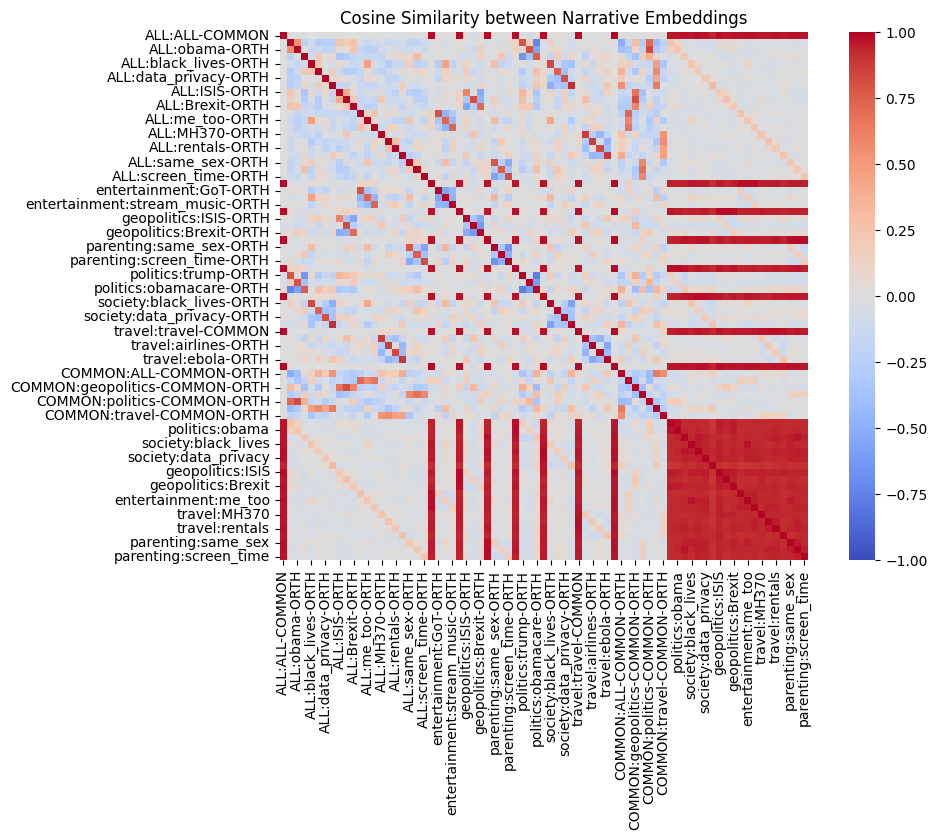

In [56]:
text_rather_than_image = False
# Create symmetric matrix of cosine similarities between narratives
print("\nComputing pairwise cosine similarities between narratives...")
narrative_names = (full_narratives_df.theme + ':' + full_narratives_df.name).to_list()
narrative_matrix = np.array(full_narratives_df['embedding'].to_list())

# Compute cosine similarity matrix
similarity_matrix = cosine_similarity(narrative_matrix)

# Display the similarity matrix
print("\nCosine Similarity Matrix between Narratives:")
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=narrative_names,
    columns=narrative_names
)
if text_rather_than_image:
  print(similarity_df.round(4))

# Visualize the similarity matrix
if not text_rather_than_image:
  plt.figure(figsize=(11, 8.5))
  sns.heatmap(similarity_df, annot=False, fmt='.4f', cmap='coolwarm',
              center=0, vmin=-1, vmax=1, square=True)
  plt.title('Cosine Similarity between Narrative Embeddings')
  plt.tight_layout()
  for ext in ['.png', '.pdf']:
    fpname = os.path.join('./results_narratives', f'narrative_similarity_matrix{ext}')
    plt.savefig(fpname, dpi=300, bbox_inches='tight')
  

# Create time series of cosines

In [57]:
# Step 1: Create combined text column
print("Creating combined text from headline and short_description...")
news_subset_df['combined_text'] = news_subset_df['headline'].fillna('') + ' ' + news_subset_df['short_description'].fillna('')
news_subset_df.shape

Creating combined text from headline and short_description...


/tmp/ipykernel_3113029/2891016169.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  news_subset_df['combined_text'] = news_subset_df['headline'].fillna('') + ' ' + news_subset_df['short_description'].fillna('')


(71655, 7)

In [58]:
# Method 1: Using groupby with week start dates
def resample_weekly_random(df, n_samples=10, random_state=42):
    """
    Resample dataframe to weekly frequency and randomly select n_samples per week.

    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame with datetime index
    n_samples : int
        Number of random samples to select per week (default: 10)
    random_state : int
        Random seed for reproducibility (default: 42)

    Returns:
    --------
    pd.DataFrame
        Resampled dataframe with random selection
    """
    # Create week identifier (start of week)
    df_copy = df.copy()
    df_copy['week'] = df_copy.index.to_period('W').to_timestamp()

    # Group by week and sample randomly
    weekly_sample = (df_copy.groupby('week', group_keys=False)
                     .apply(lambda x: x.sample(n=min(len(x), n_samples),
                                               random_state=random_state))
                     #.drop('week', axis=1)
                     )

    return weekly_sample



In [59]:
resample = False
daily_subset_df = news_subset_df.set_index('date')

if resample:
  # Apply the resampling
  resampled_subset_df = resample_weekly_random(news_subset_df, n_samples=10, random_state=42).sort_index()[:'2018-06-01']#.set_index('week')
else:
  resampled_subset_df = daily_subset_df.sort_index()[:'2018-06-01']

print(f"Original dataframe shape: {news_subset_df.shape}")
print(f"Weekly resampled shape: {resampled_subset_df.shape}")
print(f"\nDate range: {resampled_subset_df.index.min()} to {resampled_subset_df.index.max()}")

resampled_subset_df.sample(3)

Original dataframe shape: (71655, 7)
Weekly resampled shape: (67361, 6)

Date range: 2012-01-28 00:00:00 to 2018-05-26 00:00:00


,link,headline,category,short_description,authors,combined_text
date,,,,,,
2017-05-08,https://www.huffingtonpost.com/entry/questioni...,"Questioning War, Trump-Style",POLITICS,"Since the late eighteenth century, the United ...","Nick Turse, ContributorManaging Editor, TomDis...","Questioning War, Trump-Style Since the late ei..."
2017-08-30,https://www.huffingtonpost.com/entry/wednesday...,Wednesday's Morning Email: Following Houston D...,POLITICS,And a look at Trump's trip to Texas.,Lauren Weber,Wednesday's Morning Email: Following Houston D...
2013-04-06,https://www.huffingtonpost.com/entry/drew-barr...,New Mom Drew Barrymore Says Women Can't Have I...,PARENTING,"""I feel guilty all the time.""",,New Mom Drew Barrymore Says Women Can't Have I...


## Main computations (long)

In [60]:
gdir = './data_narratives'


In [61]:
articles_df = pd.read_json('./data_narratives/resampled_articles_with_embeddings.json')
articles_df['date'] = pd.to_datetime(articles_df['date'])
articles_df['embedding'] = articles_df['embedding'].apply(lambda x: np.array(x))

In [62]:
from tqdm.notebook import tqdm

print("Computing cosine similarities for all articles...")
narrative_names = (full_narratives_df.theme + ':' + full_narratives_df.name).to_list()
narrative_matrix = np.array(full_narratives_df['embedding'].to_list())

time_series_data = []
gdir = './data_narratives'

for idx, row in tqdm(articles_df.iterrows(), total=len(articles_df)):
    # Get article embedding directly from articles_df
    article_embedding = row['embedding']
    if isinstance(article_embedding, list):
        article_embedding = np.array(article_embedding)
    
    info_similarities = {
        'date': row['date'],
        'category': row['category'],
        'headline': row['headline'],
        'link': row.get('link', '')
    }
    
    # Compute cosine similarities (vectorized)
    similarities = cosine_similarity(
        article_embedding.reshape(1, -1),
        narrative_matrix
    )[0]
    
    for name, sim in zip(narrative_names, similarities):
        info_similarities[name] = float(sim)

    time_series_data.append(info_similarities)

# Save to CSV
ts_df = pd.DataFrame(time_series_data)
filepath = os.path.join(gdir, 'narrative_exposures_df.csv')
os.makedirs(gdir, exist_ok=True)
ts_df.to_csv(filepath, index=False)
print(f"✓ Saved to: {filepath}")
print(f"Shape: {ts_df.shape}")

Computing cosine similarities for all articles...


  0%|          | 0/67361 [00:00<?, ?it/s]

✓ Saved to: ./data_narratives/narrative_exposures_df.csv
Shape: (67361, 79)


In [63]:
ts_df.sample(3)

,date,category,headline,link,ALL:ALL-COMMON,ALL:trump-ORTH,ALL:obama-ORTH,ALL:obamacare-ORTH,ALL:black_lives-ORTH,ALL:shooting-ORTH,...,entertainment:GoT,entertainment:me_too,entertainment:stream_music,travel:MH370,travel:airlines,travel:rentals,travel:ebola,parenting:same_sex,parenting:parental_leave,parenting:screen_time
3008,2012-07-05,TRAVEL,"Georgetown, Colorado Has Old-Fashioned America...",https://www.huffingtonpost.com/entry/georgetow...,0.942320,-0.001803,-0.013159,-0.003610,-0.036070,-0.044674,...,0.925683,0.915681,0.922331,0.919817,0.918534,0.929496,0.901905,0.918210,0.926641,0.916049
12256,2013-08-16,TRAVEL,An Island-by-Island Guide To Caribbean Rum,https://www.huffingtonpost.com/entry/an-island...,0.949001,0.014262,0.015221,-0.008361,-0.044953,-0.076957,...,0.927797,0.919361,0.925810,0.930692,0.922564,0.927922,0.912212,0.925171,0.925816,0.915035
23698,2014-12-16,POLITICS,The Waiting Is the Hardest Part: Big Business ...,https://www.huffingtonpost.com/entry/the-waiti...,0.958486,-0.018114,0.027885,0.046122,-0.052024,-0.048372,...,0.922227,0.931335,0.925862,0.932180,0.940078,0.939316,0.908660,0.942832,0.950508,0.927271


In [64]:
# Load narrative_exposures_df from local directory (not Google Drive)
import os

gdir = './data_narratives'

# Check if file exists
filepath = os.path.join(gdir, 'narrative_exposures_df.csv')
if os.path.exists(filepath):
    ts2_df = pd.read_csv(filepath)
    print(f"Loaded narrative_exposures_df from: {filepath}")
    print(f"Shape: {ts2_df.shape}")
    ts2_df.sample(3)
else:
    print(f"File not found: {filepath}")
    print(f"Available files in {gdir}:")
    if os.path.exists(gdir):
        print(os.listdir(gdir))
    else:
        print(f"Directory {gdir} does not exist")

Loaded narrative_exposures_df from: ./data_narratives/narrative_exposures_df.csv
Shape: (67361, 79)


# Get the save data as reference

In [65]:
ts_df = ts2_df.copy()

In [66]:
def explode_colgroup(colgroup):
  group_cols = {}
  for oc in colgroup:
    g, c = oc.split(':')
    gc = group_cols.get(g, []) + [oc]
    group_cols[g] = gc
  print(f"{len(group_cols)} groups")
  return group_cols



In [67]:

ts_df['date_dt'] = pd.to_datetime(ts_df.date)
#ts_df.set_index('date_dt', inplace=True)
common_col  = ts_df.columns[ts_df.columns.str.contains('-COMMON') & ~ts_df.columns.str.contains('-ORTH')]
oth_col     = ts_df.columns[ts_df.columns.str.contains('-ORTH')]
all_coscol  = common_col.to_list() + oth_col.to_list()

orth_group_cols = explode_colgroup(oth_col)
#comm_group_cols = explode_colgroup(common_col)

ts_weekly_sum_df  = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[all_coscol].sum()
ts_weekly_mean_df = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[all_coscol].mean()
ts_weekly_sum_df.sample(5)

8 groups


,ALL:ALL-COMMON,entertainment:entertainment-COMMON,geopolitics:geopolitics-COMMON,parenting:parenting-COMMON,politics:politics-COMMON,society:society-COMMON,travel:travel-COMMON,COMMON:COMMON-COMMON,ALL:trump-ORTH,ALL:obama-ORTH,...,travel:airlines-ORTH,travel:rentals-ORTH,travel:ebola-ORTH,COMMON:ALL-COMMON-ORTH,COMMON:entertainment-COMMON-ORTH,COMMON:geopolitics-COMMON-ORTH,COMMON:parenting-COMMON-ORTH,COMMON:politics-COMMON-ORTH,COMMON:society-COMMON-ORTH,COMMON:travel-COMMON-ORTH
date_dt,,,,,,,,,,,,,,,,,,,,,
2015-05-25,167.975765,166.989830,165.155586,166.744269,165.931587,163.505004,167.934356,168.035611,2.792188,-1.111958,...,-1.931732,6.556113,-7.482133,-7.605620,7.755323,-3.386953,3.775691,0.313246,-18.610976,10.665146
2015-09-21,258.620952,257.330990,253.672866,257.168746,255.691547,251.909198,258.172891,258.723335,5.015220,-2.573670,...,-2.712107,13.191849,-12.559359,-13.117069,13.252427,-8.935985,8.744032,1.784070,-27.550523,13.503409
2012-10-22,131.879222,130.867365,129.411669,131.421676,129.912827,128.819001,131.656532,131.914121,-2.371610,-1.429666,...,-0.512052,4.258399,-4.704282,-4.310516,4.728788,-4.117622,6.486810,-1.944278,-11.455230,7.055479
2017-12-25,200.153992,198.850498,196.680388,198.952499,197.917942,195.134982,199.627591,200.233227,3.706504,-1.613533,...,-1.419747,8.265837,-9.718053,-10.151233,8.419085,-4.766527,6.242949,1.575609,-20.123129,9.122283
2016-04-25,240.190633,238.817976,235.808169,238.641244,237.702604,234.116472,239.561472,240.288113,6.010116,-0.762427,...,-2.613501,11.411092,-11.108838,-12.511117,11.242388,-7.026961,6.748855,3.099605,-24.514540,10.948201


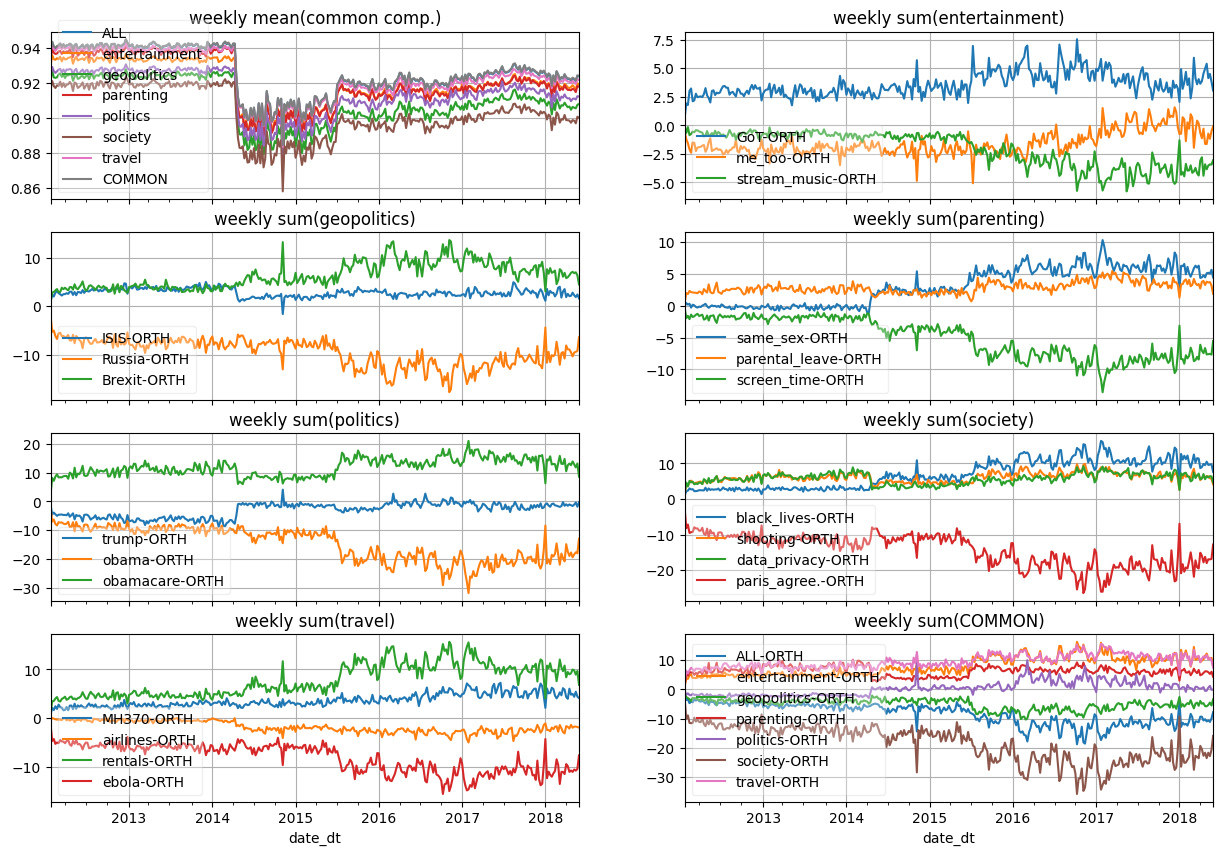

In [68]:
# plot -ORTH on one side and all the others, by theme on the other side

f, axg = plt.subplots(4, 2, figsize=(15,10), sharex=True)

for ind, (g, cs) in enumerate(orth_group_cols.items()):
  ax = axg.flat[ind]
  if ind==0:
    ts_weekly_mean_df[common_col].rename(columns={c: c.split(':')[1].replace('-COMMON', '') for c in common_col}).plot(
    ax=ax, grid=True, title='weekly mean(common comp.)',
    )
  else:
    ts_weekly_sum_df[cs].rename(columns={c: c.split(':')[1].replace('-COMMON', '') for c in cs}).plot(
    ax=ax, grid=True, title=f"weekly sum({g})",
    )
  ax.legend(fancybox=True, framealpha=0.3, loc='lower left')

#plt.tight_layout()
for ext in ['.png', '.pdf']:
  fpname = os.path.join('./results_narratives', f'components_monitor{ext}')
  plt.savefig(fpname, dpi=300, bbox_inches='tight')


In [69]:
narrative_timing_df = pandas.DataFrame(narrative_timing)
narrative_timing_df.sample(3)

,name,desc,date_start,date_end,date_max
13,MH370,Disappearance of Malaysia Airlines Flight MH37...,2014-03-08,2014-12-31,2014-03-15
1,obama,"Barack Obama’s re-election, second-term govern...",2012-01-01,2013-01-20,2012-11-06
4,shooting,Recurring mass shootings and debates over gun ...,2012-12-14,2018-12-31,2018-02-14


In [70]:
# investigate a few narratives
nar_names = ['Brexit', 'ebola', 'MH370', 'me_too', 'Russia', 'black_lives'] # 'same_sex',

from collections import namedtuple
TSandZones = namedtuple('TSandZones', ['theme', 'name', 'dates', 'sum_ts', 'mean_ts'])

# select timings
nar_timing_df = narrative_timing_df[narrative_timing_df.name.isin(nar_names)]

# get the correct theme and add it
nar_timing_df = pandas.concat([
    all_narratives_df[all_narratives_df.name.isin(nar_names)][['theme', 'name']].set_index('name'),
    nar_timing_df.set_index('name'),
    ], axis=1)


# get time series
nar_ts_dict = {}
for name, theme in nar_timing_df.theme.items():
  ts_name = f"{theme}:{name}-ORTH"
  nar_ts_dict[ts_name] = TSandZones(
      theme, name,
      nar_timing_df[nar_timing_df.index==name],
      ts_weekly_sum_df[ts_name], ts_weekly_mean_df[ts_name])

In [71]:
nar_ts_dict.keys()

dict_keys(['society:black_lives-ORTH', 'geopolitics:Russia-ORTH', 'geopolitics:Brexit-ORTH', 'entertainment:me_too-ORTH', 'travel:MH370-ORTH', 'travel:ebola-ORTH'])

In [72]:
# Create the plot
K = int(len(nar_ts_dict)/2)
L = int(len(nar_ts_dict) / K)
if not L.is_integer():
  K = K+1
  L = int(L)
fig, axg = plt.subplots(K, L, figsize=(8, 1.5*K), sharex=True)

letters = ''
for ind, (ts_name, tsz) in enumerate(nar_ts_dict.items()):
  ax = axg.flat[ind]

  # Extract data from the namedtuple
  theme  = tsz.theme
  name   = tsz.name
  sum_ts = tsz.sum_ts   # Assume this is a pandas Series with datetime index
  letters += name[0]

  # Extract date strings from the dates dataframe
  date_start_str = tsz.dates['date_start'].iloc[0]
  date_end_str   = tsz.dates['date_end'].iloc[0]
  date_max_str   = tsz.dates['date_max'].iloc[0]

  # Convert string dates to datetime
  date_start = pd.to_datetime(date_start_str)
  date_end = np.min([pd.to_datetime(date_end_str), sum_ts.index.max()])
  date_max = pd.to_datetime(date_max_str)


  # Plot the time series
  ax.plot(sum_ts.index, sum_ts.values, linewidth=2, color='steelblue', label=name)
  # Add grey zone from date_start to date_end
  ax.axvspan(date_start, date_end, alpha=0.3, color='grey', label=f'Period: {date_start_str} to {date_end_str}')
  # Add red vertical line at date_max
  ax.axvline(x=date_max, color='red', linestyle='--', linewidth=2, label=f'Max: {date_max_str}')

  ax.set_title(f"{theme.capitalize()}: {name}")
  ax.grid(True, alpha=0.3, linestyle='--')


# Formatting
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Sum Time Series', fontsize=12)
#ax.set_title(f'{theme}: {name}', fontsize=14, fontweight='bold')
#ax.legend(loc='best', fontsize=10)

# Rotate x-axis labels for better readability
#plt.xticks(rotation=45, ha='right')

plt.tight_layout()
for ext in ['.png', '.pdf']:
  fpname = os.path.join('./results_narratives', f'some_events-{len(nar_ts_dict)}-{letters}{ext}')
  plt.savefig(fpname, dpi=300, bbox_inches='tight')
  

AttributeError: 'int' object has no attribute 'is_integer'

# Plot selecting only one category of narratives

Using all data: 67361 articles
Saved: ./results_narratives/components_monitor.png
Saved: ./results_narratives/components_monitor.pdf
Filtered to category 'PARENTING': 8677 articles
Saved: ./results_narratives/components_monitor_PARENTING.png
Saved: ./results_narratives/components_monitor_PARENTING.pdf
Filtered to category 'POLITICS': 32739 articles
Saved: ./results_narratives/components_monitor_POLITICS.png
Saved: ./results_narratives/components_monitor_POLITICS.pdf
Filtered to category 'ENTERTAINMENT': 16058 articles
Saved: ./results_narratives/components_monitor_ENTERTAINMENT.png
Saved: ./results_narratives/components_monitor_ENTERTAINMENT.pdf
Filtered to category 'TRAVEL': 9887 articles
Saved: ./results_narratives/components_monitor_TRAVEL.png
Saved: ./results_narratives/components_monitor_TRAVEL.pdf


(<Figure size 1500x1000 with 8 Axes>,
 array([[<Axes: title={'center': 'weekly mean(common comp.)'}, xlabel='date_dt'>,
         <Axes: title={'center': 'weekly sum(entertainment)'}, xlabel='date_dt'>],
        [<Axes: title={'center': 'weekly sum(geopolitics)'}, xlabel='date_dt'>,
         <Axes: title={'center': 'weekly sum(parenting)'}, xlabel='date_dt'>],
        [<Axes: title={'center': 'weekly sum(politics)'}, xlabel='date_dt'>,
         <Axes: title={'center': 'weekly sum(society)'}, xlabel='date_dt'>],
        [<Axes: title={'center': 'weekly sum(travel)'}, xlabel='date_dt'>,
         <Axes: title={'center': 'weekly sum(COMMON)'}, xlabel='date_dt'>]],
       dtype=object))

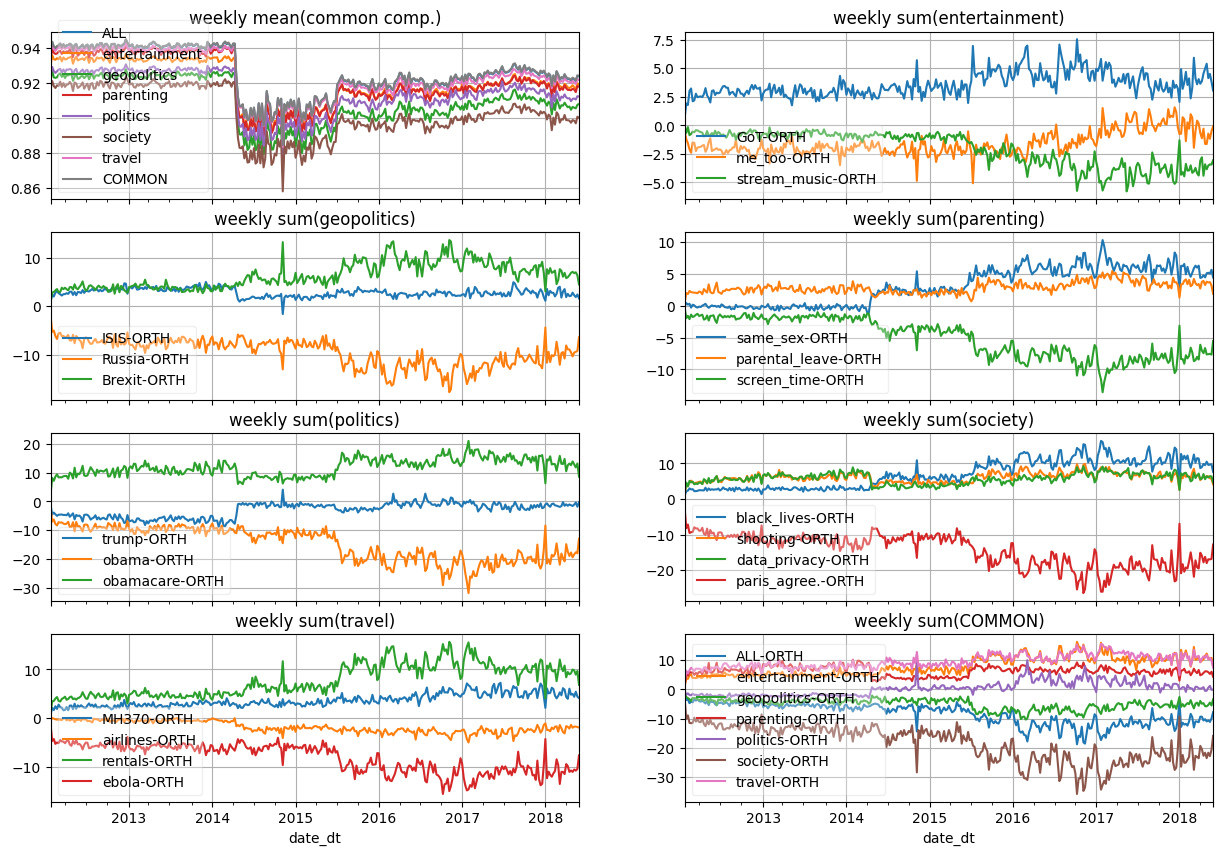

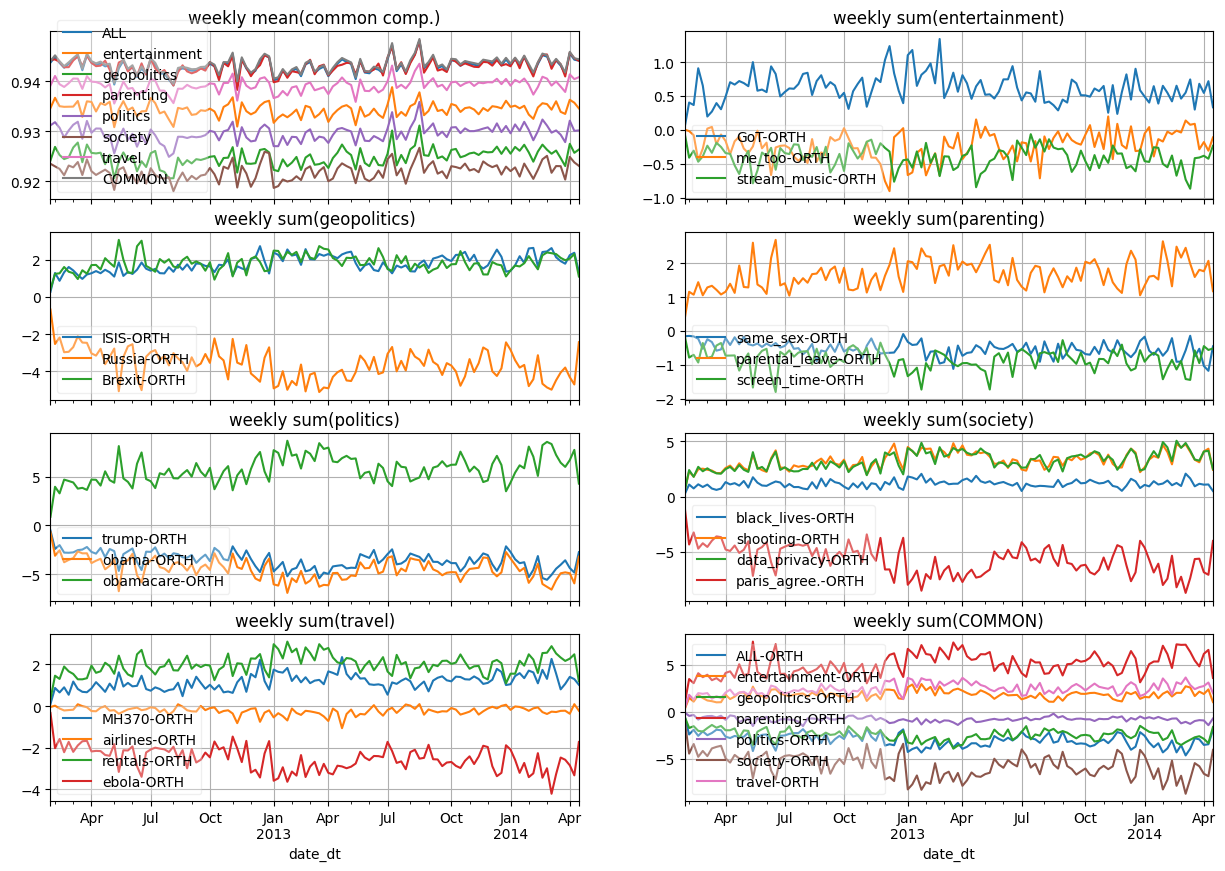

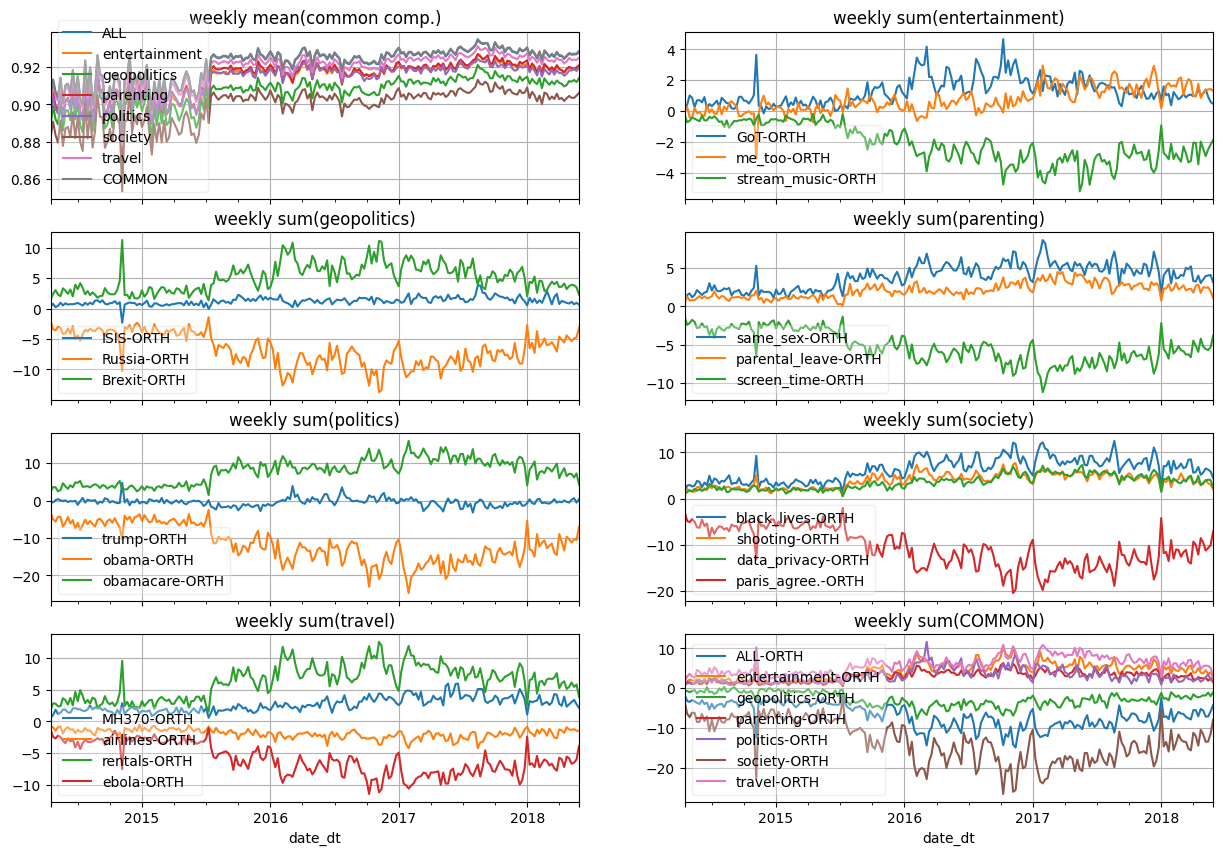

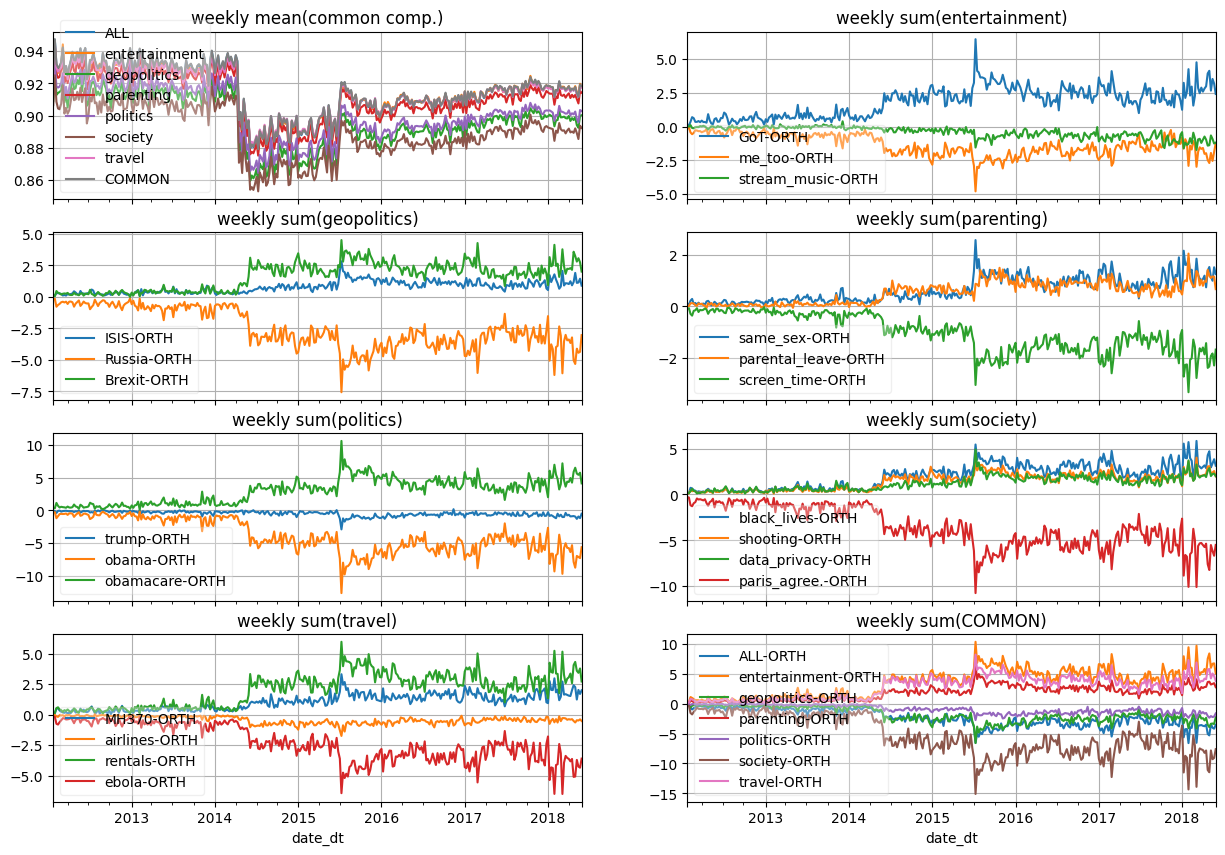

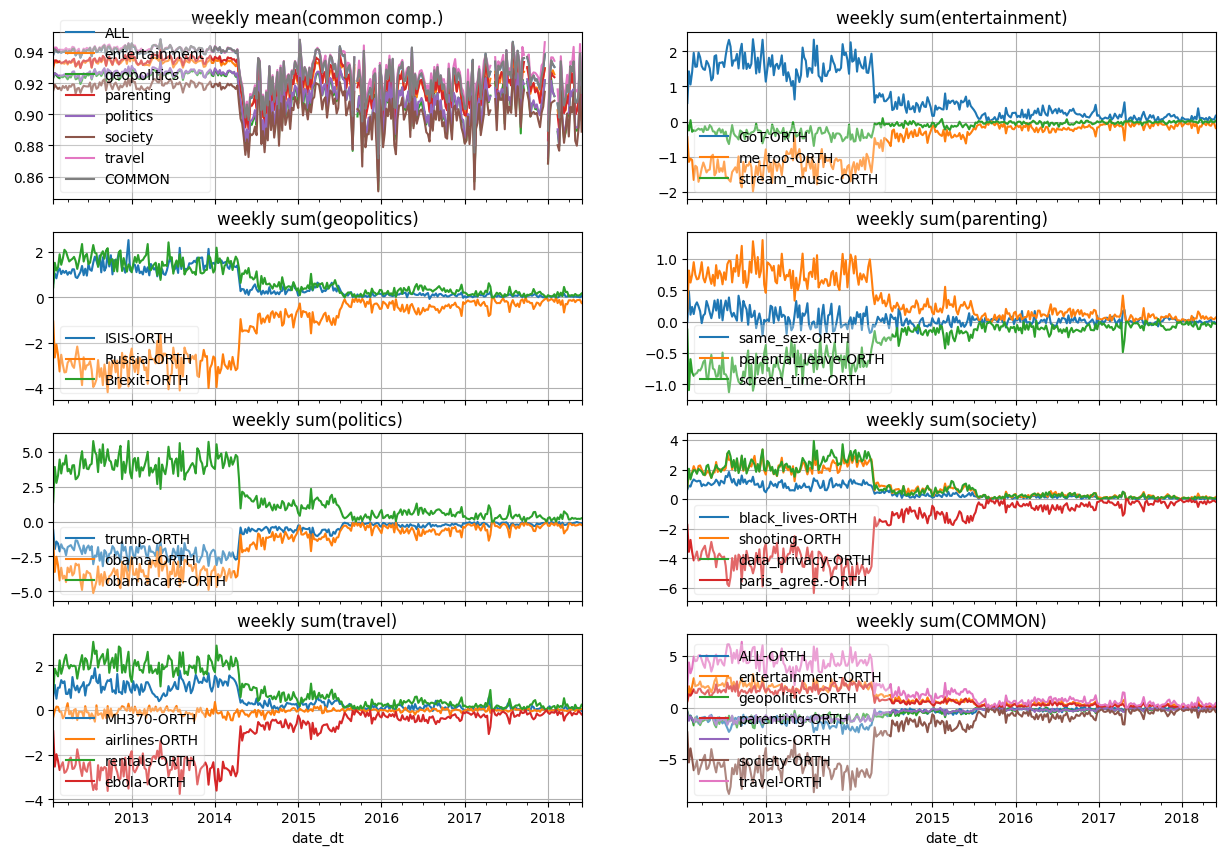

In [73]:
def plot_components_monitor_by_category(ts_df, category=None, figsize=(15, 10)):
    """
    Plot narrative components (orthogonal and common) aggregated by week.
    Restricted to a specific news category if provided.
    
    Parameters:
    -----------
    ts_df : pd.DataFrame
        Time series dataframe with narrative exposures (from narrative_exposures_df.csv)
    category : str, optional
        News category to filter by (e.g., 'POLITICS', 'ENTERTAINMENT', 'TRAVEL', 'PARENTING').
        If None, uses all data.
    figsize : tuple
        Figure size (default: (15, 10))
    
    Returns:
    --------
    fig, axg : matplotlib figure and axes
    """
    # Filter by category if specified
    if category is not None:
        ts_filtered = ts_df[ts_df['category'] == category].copy()
        print(f"Filtered to category '{category}': {len(ts_filtered)} articles")
    else:
        ts_filtered = ts_df.copy()
        print(f"Using all data: {len(ts_filtered)} articles")
    
    # Ensure date column is datetime
    ts_filtered['date_dt'] = pd.to_datetime(ts_filtered['date_dt'])
    
    # Extract narrative columns
    common_col = ts_filtered.columns[
        ts_filtered.columns.str.contains('-COMMON') & 
        ~ts_filtered.columns.str.contains('-ORTH')
    ]
    orth_col = ts_filtered.columns[ts_filtered.columns.str.contains('-ORTH')]
    all_coscol = common_col.to_list() + orth_col.to_list()
    
    # Group by theme for orthogonal columns
    orth_group_cols = {}
    for oc in orth_col:
        g, c = oc.split(':')
        if g not in orth_group_cols:
            orth_group_cols[g] = []
        orth_group_cols[g].append(oc)
    
    # Aggregate by week
    ts_weekly_sum = ts_filtered.groupby(
        pd.Grouper(key='date_dt', freq='W-MON')
    )[all_coscol].sum()
    
    ts_weekly_mean = ts_filtered.groupby(
        pd.Grouper(key='date_dt', freq='W-MON')
    )[all_coscol].mean()
    
    # Create subplots
    f, axg = plt.subplots(4, 2, figsize=figsize, sharex=True)
    
    for ind, (g, cs) in enumerate(orth_group_cols.items()):
        ax = axg.flat[ind]
        
        if ind == 0:
            # Plot common components with mean
            ts_weekly_mean[common_col].rename(
                columns={c: c.split(':')[1].replace('-COMMON', '') for c in common_col}
            ).plot(ax=ax, grid=True, title='weekly mean(common comp.)')
        else:
            # Plot orthogonal components with sum
            ts_weekly_sum[cs].rename(
                columns={c: c.split(':')[1].replace('-COMMON', '') for c in cs}
            ).plot(ax=ax, grid=True, title=f"weekly sum({g})")
        
        ax.legend(fancybox=True, framealpha=0.3, loc='lower left')
    
    # Save figure
    category_suffix = f"_{category}" if category else ""
    for ext in ['.png', '.pdf']:
        fpname = os.path.join(
            './results_narratives', 
            f'components_monitor{category_suffix}{ext}'
        )
        os.makedirs('./results_narratives', exist_ok=True)
        f.savefig(fpname, dpi=300, bbox_inches='tight')
        print(f"Saved: {fpname}")
    
    return f, axg


# Exemples d'utilisation :

# 1. Tous les articles (sans restriction)
plot_components_monitor_by_category(ts_df)

# 2. Seulement les articles PARENTING
plot_components_monitor_by_category(ts_df, category='PARENTING')

# 3. Seulement les articles POLITICS
plot_components_monitor_by_category(ts_df, category='POLITICS')

# 4. Seulement les articles ENTERTAINMENT
plot_components_monitor_by_category(ts_df, category='ENTERTAINMENT')

# 5. Seulement les articles TRAVEL
plot_components_monitor_by_category(ts_df, category='TRAVEL')

# Maths around orthogonality and cosine similarity

**Core definitions**

Global centroid: $c = \frac1N \sum_{k,i} x_{k,i}$

Chapter centroid: $c_k = \frac1N_k \sum_i x_{k,i}$

Chapter residual (orthogonal projection with respect to the chapter centroid): $p_{k,i} = x_{k,i} - c_k$

Chapter deviation: $d_k = c_k - c$

# Appendix: PCA computations

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Assuming temp_narrative_matrix is already created
# temp_narrative_matrix = [narrative_embeddings[name] for name in narratives.keys()]

# Convert to numpy array (shape: 3 x 768)
narrative_matrix = np.array(temp_narrative_matrix)
print(f"Original narrative matrix shape: {narrative_matrix.shape}")

# Step 1: Perform PCA to get the first principal component
print("\n=== Step 1: PCA Analysis ===")

# Initialize PCA with 1 component
pca = PCA(n_components=1)

# Fit PCA on the narrative embeddings
pca.fit(narrative_matrix)

# Get the first principal component (direction vector)
first_pc = pca.components_[0]  # Shape: (768,)
print(f"First principal component shape: {first_pc.shape}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_[0]:.4f}")
print(f"Explained variance: {pca.explained_variance_[0]:.4f}")

# Project narratives onto the first PC
projections_on_pc1 = pca.transform(narrative_matrix)  # Shape: (3, 1)
print(f"\nProjections onto first PC:\n{projections_on_pc1.flatten()}")
cosine_with_pc1 = cosine_similarity(narrative_matrix, first_pc.reshape(1, -1))
print(f"\nCosine similarity with PC1:\n{cosine_with_pc1.flatten()}")

# Step 2: Project embeddings onto the orthogonal complement of PC1
print("\n=== Step 2: Orthogonal Projection ===")

def project_onto_orthogonal_complement(embeddings, principal_component):
    """
    Project embeddings onto the orthogonal complement of a principal component.

    This removes the component of each embedding that lies along the principal
    component direction, leaving only the orthogonal part.

    Parameters:
    -----------
    embeddings : np.ndarray
        Matrix of embeddings (n_samples x n_features)
    principal_component : np.ndarray
        The principal component vector (n_features,)

    Returns:
    --------
    np.ndarray
        Embeddings projected onto orthogonal complement (n_samples x n_features)
    """
    # Normalize the principal component (should already be normalized, but ensure it)
    pc_normalized = principal_component / np.linalg.norm(principal_component)

    # For each embedding, compute projection onto PC1
    # projection = (embedding · pc) * pc
    projections = np.dot(embeddings, pc_normalized)  # Shape: (n_samples,)

    # Compute the component along PC1
    component_along_pc1 = np.outer(projections, pc_normalized)  # Shape: (n_samples, n_features)

    # Subtract to get orthogonal component
    orthogonal_embeddings = embeddings - component_along_pc1

    return orthogonal_embeddings

# Apply orthogonal projection
narrative_embeddings_orthogonal = project_onto_orthogonal_complement(
    narrative_matrix,
    first_pc
)

print(f"Orthogonal embeddings shape: {narrative_embeddings_orthogonal.shape}")

# Verify orthogonality: dot product with PC1 should be ~0
dot_products = np.dot(narrative_embeddings_orthogonal, first_pc)
print(f"\nVerification - Dot products with PC1 (should be ~0):")
print(f"  {dot_products}")
print(f"  Max absolute value: {np.abs(dot_products).max():.2e}")

# Compare norms
original_norms = np.linalg.norm(narrative_matrix, axis=1)
orthogonal_norms = np.linalg.norm(narrative_embeddings_orthogonal, axis=1)

print(f"\nNorm comparison:")
print(f"Original norms: {original_norms}")
print(f"Orthogonal norms: {orthogonal_norms}")
print(f"Percentage of original norm retained: {(orthogonal_norms / original_norms * 100).round(2)}")
